# 07 – Classification (Phân loại): dự đoán phim IMDb điểm cao hay thấp

**Người phụ trách:** Thành viên 4 – Duy

**Đầu vào:** `data/processed/imdb_for_classification.csv` (tạo từ `04_feature_engineering.ipynb`).

**Đầu ra:** `models/classification/classification_pipeline.pkl`.

**Bài toán:** dự đoán nhãn `rating_class` của một bộ phim:

| Nhãn | Ý nghĩa |
| --- | --- |
| `High` | `imdb_rating >= 7` |
| `Low` | `imdb_rating < 7` |

**Hai thuật toán:** Logistic Regression (hồi quy logistic) và Decision Tree Classifier (cây quyết định phân loại).

**Quy trình:**
1. Đọc dữ liệu và kiểm tra rò rỉ dữ liệu (data leakage).
2. Kiểm tra mất cân bằng lớp (class imbalance).
3. Chia train/test theo tầng (stratified split).
4. Xây pipeline tiền xử lý (preprocessing pipeline) và huấn luyện hai mô hình.
5. Đánh giá bằng Accuracy, Precision, Recall, F1-score và vẽ Confusion Matrix (ma trận nhầm lẫn).
6. So sánh mô hình, phân tích lỗi và lưu pipeline tốt nhất.

> **Lưu ý rò rỉ dữ liệu:** nhãn được sinh ra từ `imdb_rating`, nên `imdb_rating` **không được** nằm trong các đặc trưng (features). Notebook 04 đã loại cột này khỏi file classification, ở đây ta kiểm tra lại bằng `assert`.

## 7.1. Import thư viện và cấu hình

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay,
                             classification_report)
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

RANDOM_STATE = 42
POS_LABEL = 'High'          # lớp dương (positive class)
LABELS = ['Low', 'High']    # thứ tự hiển thị trong Confusion Matrix

## 7.2. Đọc dữ liệu

In [2]:
ROOT = Path.cwd()
if ROOT.name.lower() == 'notebooks':
    ROOT = ROOT.parent

DATA_PATH = ROOT / 'data' / 'processed' / 'imdb_for_classification.csv'
MODEL_DIR = ROOT / 'models' / 'classification'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError('Chạy 04_feature_engineering.ipynb trước để tạo imdb_for_classification.csv!')

df = pd.read_csv(DATA_PATH)
print('Kích thước:', df.shape)
display(df.head())

Kích thước: (3716, 31)


,title,year,duration_minutes,metascore,genre_count,cast_count,title_length,genre_action,genre_adventure,genre_animation,genre_biography,genre_comedy,genre_crime,genre_documentary,genre_drama,genre_family,genre_fantasy,genre_history,genre_horror,genre_music,genre_musical,genre_mystery,genre_romance,genre_sci_fi,genre_sport,genre_thriller,genre_war,genre_western,primary_genre,certificates,rating_class
0,End of the Spear,2005,108.0,45.0,1,1,16,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Adventure,PG-13,Low
1,Elvira Madigan,1967,91.0,66.0,1,1,14,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Biography,PG,High
2,The Kid Stays in the Picture,2002,93.0,75.0,1,1,28,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Documentary,R,High
3,It Ain't Over,2022,99.0,79.0,1,1,13,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Documentary,PG,High
4,Mahler,1974,115.0,66.0,1,1,6,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Biography,PG,High


In [3]:
print('Kiểu dữ liệu:')
print(df.dtypes.value_counts())
print()

missing = (df.isna().sum().to_frame('so_dong_thieu')
             .assign(ty_le_pct=lambda t: (t['so_dong_thieu'] / len(df) * 100).round(2))
             .query('so_dong_thieu > 0')
             .sort_values('so_dong_thieu', ascending=False))
print('Các cột còn thiếu dữ liệu (sẽ được điền trong pipeline, chỉ học từ tập train):')
display(missing)

Kiểu dữ liệu:
int64      25
str         4
float64     2
Name: count, dtype: int64

Các cột còn thiếu dữ liệu (sẽ được điền trong pipeline, chỉ học từ tập train):


,so_dong_thieu,ty_le_pct


## 7.3. Xác định nhãn và đặc trưng, kiểm tra rò rỉ dữ liệu

Danh sách đặc trưng giữ **đúng như notebook 04** để pipeline của nhóm thống nhất:

- Biến số (numerical): `year`, `duration_minutes`, `metascore`, `genre_count`, `cast_count`, `title_length`.
- 21 cột cờ thể loại (binary): `genre_action`, `genre_drama`, ...
- Biến phân loại (categorical): `primary_genre`, `certificates`.

In [4]:
TARGET = 'rating_class'

feature_num = ['year', 'duration_minutes', 'metascore', 'genre_count',
               'cast_count', 'title_length']
feature_cat = ['primary_genre', 'certificates']
genre_binary_cols = [c for c in df.columns
                     if c.startswith('genre_') and c != 'genre_count']
features = feature_num + genre_binary_cols + feature_cat

# --- Kiểm tra cột và rò rỉ dữ liệu ---
missing_cols = [c for c in features + [TARGET] if c not in df.columns]
assert not missing_cols, f'Thiếu cột trong file CSV: {missing_cols}'
assert 'imdb_rating' not in features, 'Rò rỉ nhãn: imdb_rating nằm trong features!'
assert 'imdb_rating' not in df.columns, 'imdb_rating không nên có trong file classification.'
assert TARGET not in features and 'title' not in features

# Đảm bảo cột phân loại là object và thiếu dữ liệu là NaN chuẩn
for col in feature_cat:
    df[col] = df[col].astype(object).where(df[col].notna(), np.nan)

# Bỏ dòng không có nhãn (nếu còn)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
assert set(df[TARGET].unique()) <= set(LABELS)

print(f'Số đặc trưng số: {len(feature_num)} | cờ thể loại: {len(genre_binary_cols)} | phân loại: {len(feature_cat)}')
print('Tổng số đặc trưng đầu vào:', len(features))

Số đặc trưng số: 6 | cờ thể loại: 21 | phân loại: 2
Tổng số đặc trưng đầu vào: 29


## 7.4. Kiểm tra mất cân bằng lớp (Class Imbalance)

Nếu một lớp chiếm quá nhiều thì mô hình có thể đạt Accuracy cao chỉ bằng cách luôn đoán lớp đông hơn, nên cần xem thêm Precision, Recall và F1-score.

,so_phim,ty_le_pct
rating_class,,
Low,2090,56.24
High,1626,43.76


Tỉ lệ lớp đông / lớp ít (imbalance ratio): 1.29


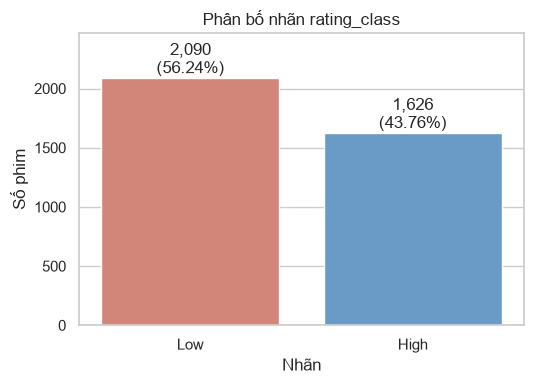

Dữ liệu tương đối cân bằng; vẫn dùng stratified split và class_weight="balanced" cho an toàn.


In [5]:
counts = df[TARGET].value_counts().reindex(LABELS)
percent = (counts / counts.sum() * 100).round(2)
summary = pd.DataFrame({'so_phim': counts, 'ty_le_pct': percent})
display(summary)

imbalance_ratio = counts.max() / counts.min()
print(f'Tỉ lệ lớp đông / lớp ít (imbalance ratio): {imbalance_ratio:.2f}')

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.barplot(x=counts.index, y=counts.values, palette=['#e07b6a', '#5b9bd5'], ax=ax)
for i, (n, p) in enumerate(zip(counts.values, percent.values)):
    ax.text(i, n, f'{n:,}\n({p}%)', ha='center', va='bottom')
ax.set_title('Phân bố nhãn rating_class')
ax.set_xlabel('Nhãn')
ax.set_ylabel('Số phim')
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.show()

if imbalance_ratio >= 1.5:
    print('Dữ liệu có mất cân bằng lớp rõ rệt -> dùng stratified split và class_weight="balanced".')
else:
    print('Dữ liệu tương đối cân bằng; vẫn dùng stratified split và class_weight="balanced" cho an toàn.')

## 7.5. Chia tập train/test

Dùng `stratify=y` để tỉ lệ High/Low trong tập train và test giống tập gốc.

In [6]:
X = df[features]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

split_info = pd.DataFrame({
    'train_so_phim': y_train.value_counts().reindex(LABELS),
    'train_ty_le_pct': (y_train.value_counts(normalize=True).reindex(LABELS) * 100).round(2),
    'test_so_phim': y_test.value_counts().reindex(LABELS),
    'test_ty_le_pct': (y_test.value_counts(normalize=True).reindex(LABELS) * 100).round(2),
})
print('Train:', X_train.shape, '| Test:', X_test.shape)
display(split_info)

Train: (2972, 29) | Test: (744, 29)


,train_so_phim,train_ty_le_pct,test_so_phim,test_ty_le_pct
rating_class,,,,
Low,1672,56.26,418,56.18
High,1300,43.74,326,43.82


## 7.6. Pipeline tiền xử lý

Mọi bước học tham số đều **chỉ fit trên tập train** để tránh rò rỉ dữ liệu:

- Biến số và cờ thể loại: điền thiếu bằng median (trung vị), sau đó `StandardScaler` (chuẩn hóa).
- Biến phân loại: điền thiếu bằng giá trị phổ biến nhất, sau đó `OneHotEncoder` (mã hóa one-hot).

Decision Tree không cần chuẩn hóa nhưng vẫn dùng chung preprocessing cho hai mô hình để so sánh công bằng.

In [7]:
def make_preprocessor():
    numeric_transform = Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scaler', StandardScaler()),
    ])
    category_transform = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ])
    return ColumnTransformer([
        ('numerical', numeric_transform, feature_num + genre_binary_cols),
        ('categorical', category_transform, feature_cat),
    ])


def make_pipeline(model):
    return Pipeline([('preprocess', make_preprocessor()), ('model', model)])

## 7.7. Huấn luyện mô hình

- **Baseline (mô hình cơ sở):** `DummyClassifier` luôn đoán lớp đông nhất, dùng để thấy Accuracy một mình chưa đủ.
- **Logistic Regression:** thử các giá trị `C` (độ mạnh regularization, tức điều chuẩn hóa, càng nhỏ càng mạnh).
- **Decision Tree Classifier:** thử `max_depth` và `min_samples_leaf` để hạn chế overfitting (quá khớp).

Tìm tham số bằng `GridSearchCV` với 5-fold stratified cross-validation (kiểm định chéo), tối ưu `f1_macro`. Cả hai mô hình dùng `class_weight='balanced'` để bù mất cân bằng lớp.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# --- Baseline ---
baseline = make_pipeline(DummyClassifier(strategy='most_frequent'))
baseline.fit(X_train, y_train)

# --- Logistic Regression ---
lr_search = GridSearchCV(
    make_pipeline(LogisticRegression(class_weight='balanced', max_iter=2000,
                                     random_state=RANDOM_STATE)),
    param_grid={'model__C': [0.01, 0.1, 1, 10]},
    scoring='f1_macro', cv=cv, n_jobs=-1,
)
lr_search.fit(X_train, y_train)

# --- Decision Tree ---
dt_search = GridSearchCV(
    make_pipeline(DecisionTreeClassifier(class_weight='balanced',
                                         random_state=RANDOM_STATE)),
    param_grid={'model__max_depth': [3, 5, 7, 10],
                'model__min_samples_leaf': [5, 10, 20, 50]},
    scoring='f1_macro', cv=cv, n_jobs=-1,
)
dt_search.fit(X_train, y_train)

lr_model = lr_search.best_estimator_
dt_model = dt_search.best_estimator_

print('Logistic Regression - tham số tốt nhất:', lr_search.best_params_,
      '| CV F1-macro: %.4f' % lr_search.best_score_)
print('Decision Tree       - tham số tốt nhất:', dt_search.best_params_,
      '| CV F1-macro: %.4f' % dt_search.best_score_)

Logistic Regression - tham số tốt nhất: {'model__C': 1} | CV F1-macro: 0.7174
Decision Tree       - tham số tốt nhất: {'model__max_depth': 5, 'model__min_samples_leaf': 50} | CV F1-macro: 0.7349


## 7.8. Đánh giá bằng Accuracy, Precision, Recall, F1-score

Lớp dương (positive class) là `High`:

- **Accuracy:** tỉ lệ dự đoán đúng trên toàn bộ phim.
- **Precision:** trong số phim dự đoán `High`, bao nhiêu phim thật sự `High`.
- **Recall:** trong số phim thật sự `High`, mô hình tìm được bao nhiêu.
- **F1-score:** trung bình điều hòa của Precision và Recall.
- **F1-macro:** trung bình F1 của cả hai lớp, ít bị lệch khi mất cân bằng lớp.

In [9]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    pred_te = model.predict(X_te)
    pred_tr = model.predict(X_tr)
    result = {
        'Mô hình': name,
        'Accuracy': accuracy_score(y_te, pred_te),
        'Precision (High)': precision_score(y_te, pred_te, pos_label=POS_LABEL, zero_division=0),
        'Recall (High)': recall_score(y_te, pred_te, pos_label=POS_LABEL, zero_division=0),
        'F1 (High)': f1_score(y_te, pred_te, pos_label=POS_LABEL, zero_division=0),
        'F1-macro': f1_score(y_te, pred_te, average='macro', zero_division=0),
        'Train Accuracy': accuracy_score(y_tr, pred_tr),
    }
    if hasattr(model, 'predict_proba'):
        idx = list(model.classes_).index(POS_LABEL)
        result['ROC-AUC'] = roc_auc_score(y_te == POS_LABEL, model.predict_proba(X_te)[:, idx])
    return result


results = pd.DataFrame([
    evaluate('Baseline (đoán lớp đông nhất)', baseline, X_train, y_train, X_test, y_test),
    evaluate('Logistic Regression', lr_model, X_train, y_train, X_test, y_test),
    evaluate('Decision Tree', dt_model, X_train, y_train, X_test, y_test),
]).set_index('Mô hình')

display(results.round(4))

,Accuracy,Precision (High),Recall (High),F1 (High),F1-macro,Train Accuracy,ROC-AUC
Mô hình,,,,,,,
Baseline (đoán lớp đông nhất),0.5618,0.0000,0.0000,0.0000,0.3597,0.5626,0.5000
Logistic Regression,0.7164,0.6923,0.6350,0.6624,0.7090,0.7355,0.7723
Decision Tree,0.7285,0.7168,0.6288,0.6699,0.7197,0.7426,0.7802


In [10]:
for name, model in [('Logistic Regression', lr_model), ('Decision Tree', dt_model)]:
    print('=' * 60)
    print(name)
    print(classification_report(y_test, model.predict(X_test), labels=LABELS, digits=4, zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

         Low     0.7326    0.7799    0.7555       418
        High     0.6923    0.6350    0.6624       326

    accuracy                         0.7164       744
   macro avg     0.7124    0.7074    0.7090       744
weighted avg     0.7149    0.7164    0.7147       744

Decision Tree
              precision    recall  f1-score   support

         Low     0.7358    0.8062    0.7694       418
        High     0.7168    0.6288    0.6699       326

    accuracy                         0.7285       744
   macro avg     0.7263    0.7175    0.7197       744
weighted avg     0.7275    0.7285    0.7258       744



## 7.9. Confusion Matrix (ma trận nhầm lẫn)

Hàng là nhãn thật, cột là nhãn dự đoán. Hai ô chéo là dự đoán đúng; ô `Low -> High` là báo động giả (False Positive), ô `High -> Low` là bỏ sót (False Negative).

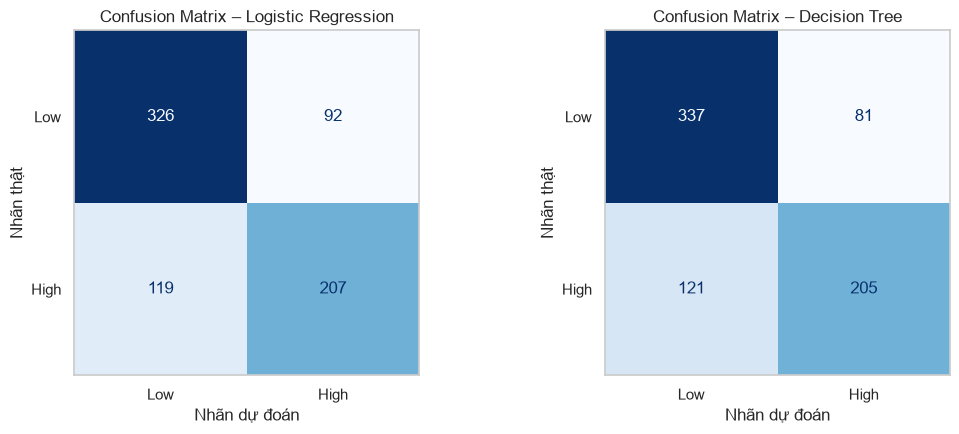

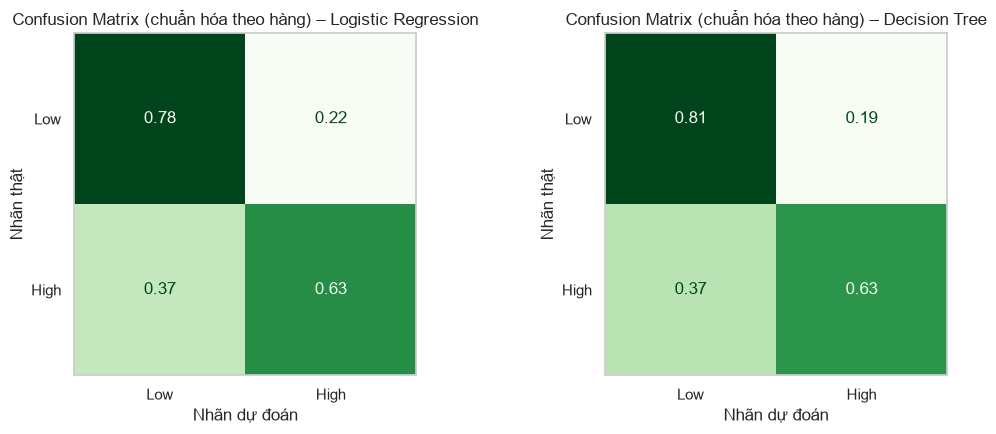

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, [('Logistic Regression', lr_model),
                                    ('Decision Tree', dt_model)]):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, labels=LABELS, cmap='Blues',
        values_format='d', ax=ax, colorbar=False)
    ax.set_title(f'Confusion Matrix – {name}')
    ax.set_xlabel('Nhãn dự đoán')
    ax.set_ylabel('Nhãn thật')
    ax.grid(False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, [('Logistic Regression', lr_model),
                                    ('Decision Tree', dt_model)]):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, labels=LABELS, cmap='Greens',
        normalize='true', values_format='.2f', ax=ax, colorbar=False)
    ax.set_title(f'Confusion Matrix (chuẩn hóa theo hàng) – {name}')
    ax.set_xlabel('Nhãn dự đoán')
    ax.set_ylabel('Nhãn thật')
    ax.grid(False)
plt.tight_layout()
plt.show()

## 7.10. So sánh hai mô hình

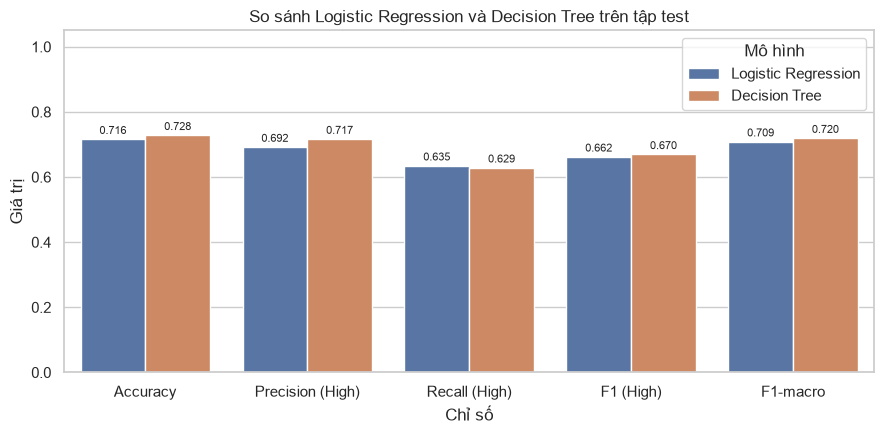

Mô hình tốt hơn theo F1-macro: Decision Tree (F1-macro = 0.7197, Accuracy = 0.7285)

Chênh lệch Train Accuracy - Test Accuracy (càng lớn càng có nguy cơ overfitting):
Mô hình
Logistic Regression    0.0191
Decision Tree          0.0141


In [12]:
metrics_to_plot = ['Accuracy', 'Precision (High)', 'Recall (High)', 'F1 (High)', 'F1-macro']
plot_df = (results.loc[['Logistic Regression', 'Decision Tree'], metrics_to_plot]
                  .T.reset_index().melt(id_vars='index', var_name='Mô hình', value_name='Giá trị')
                  .rename(columns={'index': 'Chỉ số'}))

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_df, x='Chỉ số', y='Giá trị', hue='Mô hình', ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title('So sánh Logistic Regression và Decision Tree trên tập test')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)
plt.tight_layout()
plt.show()

# Chọn mô hình tốt nhất theo F1-macro trên tập test
candidates = results.loc[['Logistic Regression', 'Decision Tree']]
best_name = candidates['F1-macro'].idxmax()
best_model = {'Logistic Regression': lr_model, 'Decision Tree': dt_model}[best_name]
print(f'Mô hình tốt hơn theo F1-macro: {best_name} '
      f'(F1-macro = {candidates.loc[best_name, "F1-macro"]:.4f}, '
      f'Accuracy = {candidates.loc[best_name, "Accuracy"]:.4f})')

gap = (candidates['Train Accuracy'] - candidates['Accuracy']).round(4)
print('\nChênh lệch Train Accuracy - Test Accuracy (càng lớn càng có nguy cơ overfitting):')
print(gap.to_string())

## 7.11. Đặc trưng nào ảnh hưởng nhiều nhất?

- Logistic Regression: hệ số (coefficient) dương đẩy dự đoán về `High`, hệ số âm đẩy về `Low` (các biến số đã được chuẩn hóa nên so sánh được tương đối).
- Decision Tree: `feature_importances_` cho biết đặc trưng nào giảm độ tạp (impurity) nhiều nhất.

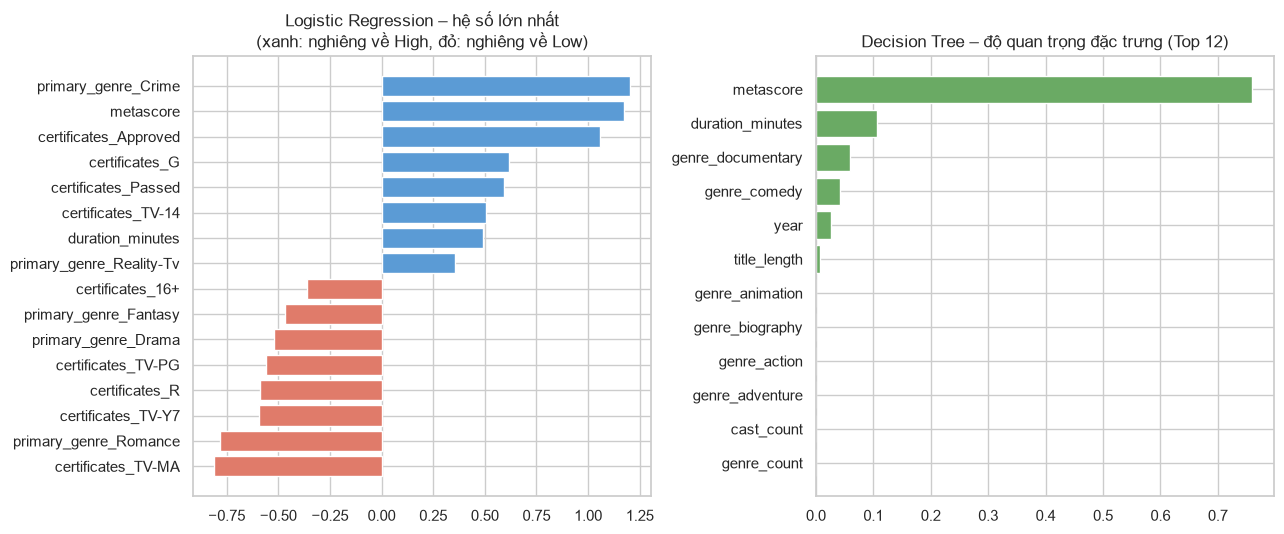

In [13]:
feature_names = lr_model.named_steps['preprocess'].get_feature_names_out()
feature_names = np.array([n.split('__', 1)[-1] for n in feature_names])

# Logistic Regression
lr_clf = lr_model.named_steps['model']
coef = lr_clf.coef_[0]                           # dương = nghiêng về lớp classes_[1]
if lr_clf.classes_[1] != POS_LABEL:              # classes_ xếp theo alphabet: ['High', 'Low']
    coef = -coef                                 # đổi dấu để dương = nghiêng về High
lr_imp = pd.Series(coef, index=feature_names)
lr_top = pd.concat([lr_imp.nlargest(8), lr_imp.nsmallest(8)]).sort_values()

# Decision Tree
dt_imp = pd.Series(dt_model.named_steps['model'].feature_importances_, index=feature_names)
dt_top = dt_imp.nlargest(12).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
colors = ['#e07b6a' if v < 0 else '#5b9bd5' for v in lr_top.values]
axes[0].barh(lr_top.index, lr_top.values, color=colors)
axes[0].set_title('Logistic Regression – hệ số lớn nhất\n(xanh: nghiêng về High, đỏ: nghiêng về Low)')
axes[1].barh(dt_top.index, dt_top.values, color='#6aaa64')
axes[1].set_title('Decision Tree – độ quan trọng đặc trưng (Top 12)')
plt.tight_layout()
plt.show()

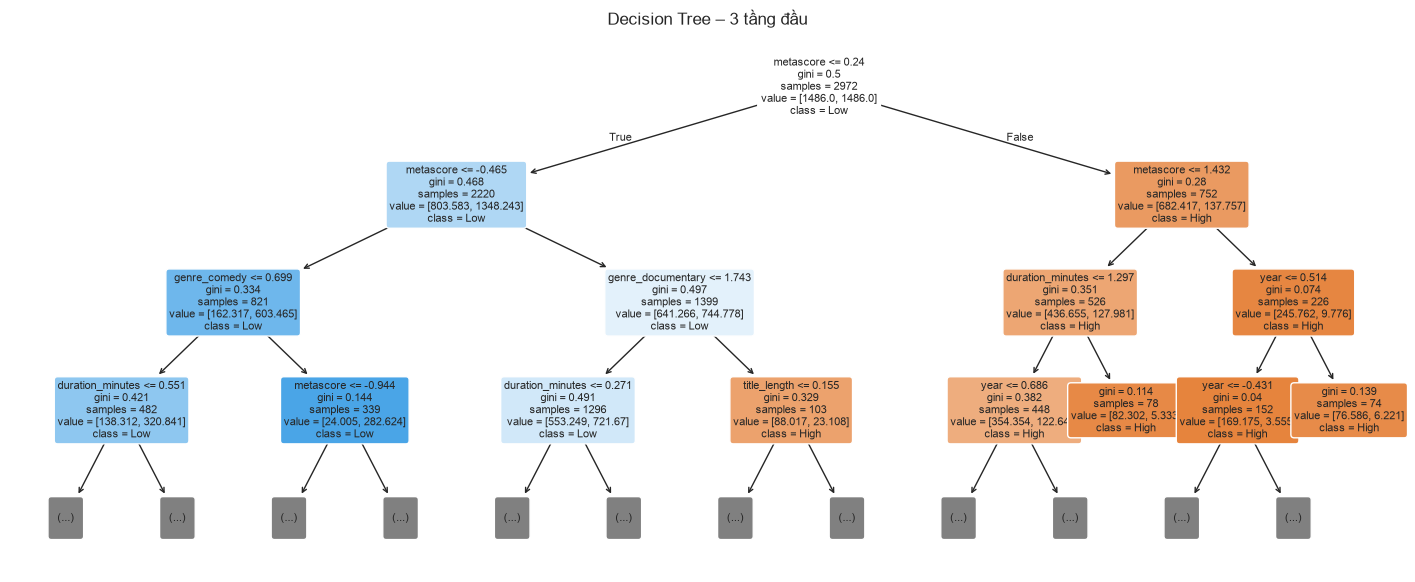

In [14]:
# Cấu trúc 3 tầng đầu của cây quyết định
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(dt_model.named_steps['model'], max_depth=3, feature_names=feature_names,
          class_names=list(dt_model.named_steps['model'].classes_),
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title('Decision Tree – 3 tầng đầu')
plt.show()

## 7.12. Phân tích lỗi

Xem các phim mà mô hình tốt nhất dự đoán sai. Thường lỗi tập trung ở các phim có điểm gần ngưỡng 7.0.

In [15]:
test_view = df.loc[X_test.index, ['title', 'year', 'primary_genre', 'metascore']].copy()
test_view['nhan_that'] = y_test.values
test_view['nhan_du_doan'] = best_model.predict(X_test)
idx_high = list(best_model.classes_).index(POS_LABEL)
test_view['xac_suat_High'] = best_model.predict_proba(X_test)[:, idx_high].round(3)

wrong = test_view[test_view['nhan_that'] != test_view['nhan_du_doan']]
print(f'{best_name}: sai {len(wrong):,}/{len(test_view):,} phim ({len(wrong) / len(test_view):.1%})')

print('\nBáo động giả (thật: Low, đoán: High):', ((wrong['nhan_that'] == 'Low')).sum())
print('Bỏ sót     (thật: High, đoán: Low):', ((wrong['nhan_that'] == 'High')).sum())

display(wrong.sample(min(10, len(wrong)), random_state=RANDOM_STATE))

Decision Tree: sai 202/744 phim (27.2%)

Báo động giả (thật: Low, đoán: High): 81
Bỏ sót     (thật: High, đoán: Low): 121


,title,year,primary_genre,metascore,nhan_that,nhan_du_doan,xac_suat_High
1314,RiffTrax: Firehead,2013,Action,66.0,High,Low,0.457
1154,19,1987,Fantasy,66.0,High,Low,0.339
867,Saw X,2023,Horror,60.0,Low,High,0.592
1318,Rappaccini's Daughter,2013,Fantasy,66.0,High,Low,0.457
88,Flash of Genius,2008,Biography,57.0,High,Low,0.388
481,The Survivor,2021,Biography,71.0,Low,High,0.563
1836,LICK,2019,Animation,66.0,High,Low,0.457
1691,An Human,2011,Drama,66.0,High,Low,0.339
485,Greater,2016,Biography,35.0,High,Low,0.399
921,Izo,2004,Action,66.0,Low,High,0.592


## 7.13. Lưu pipeline tốt nhất

Pipeline gồm cả tiền xử lý và mô hình, nên Streamlit (Thành viên 5) chỉ cần nạp file này rồi truyền một `DataFrame` có đúng các cột đầu vào.

In [16]:
PIPELINE_PATH = MODEL_DIR / 'classification_pipeline.pkl'
joblib.dump(best_model, PIPELINE_PATH)
print('Đã lưu:', PIPELINE_PATH, f'({PIPELINE_PATH.stat().st_size / 1024:.1f} KB)')

# Kiểm tra nạp lại và dự đoán thử
loaded = joblib.load(PIPELINE_PATH)
sample = X_test.head(3)
print('\nDự đoán thử:', loaded.predict(sample))
print('Xác suất High:', loaded.predict_proba(sample)[:, list(loaded.classes_).index(POS_LABEL)].round(3))

print('\nCác cột đầu vào mà pipeline yêu cầu (gửi cho Thành viên 5):')
print(list(loaded.feature_names_in_))

Đã lưu: t:\HocKi5\AI\DUANNHOM\models\classification\classification_pipeline.pkl (10.3 KB)

Dự đoán thử: ['High' 'Low' 'Low']
Xác suất High: [0.829 0.457 0.198]

Các cột đầu vào mà pipeline yêu cầu (gửi cho Thành viên 5):
['year', 'duration_minutes', 'metascore', 'genre_count', 'cast_count', 'title_length', 'genre_action', 'genre_adventure', 'genre_animation', 'genre_biography', 'genre_comedy', 'genre_crime', 'genre_documentary', 'genre_drama', 'genre_family', 'genre_fantasy', 'genre_history', 'genre_horror', 'genre_music', 'genre_musical', 'genre_mystery', 'genre_romance', 'genre_sci_fi', 'genre_sport', 'genre_thriller', 'genre_war', 'genre_western', 'primary_genre', 'certificates']


## 7.14. Kết luận và hạn chế

**Kết luận** (đối chiếu với bảng ở mục 7.8 và biểu đồ ở mục 7.10 sau khi chạy xong):

- Nêu mô hình tốt hơn và các chỉ số chính của nó (Accuracy, Precision, Recall, F1).
- So sánh với baseline để chứng minh mô hình học được thông tin, không chỉ đoán lớp đông.
- Nhận xét Confusion Matrix: mô hình mắc lỗi loại nào nhiều hơn (báo động giả hay bỏ sót).
- Nhận xét các đặc trưng quan trọng (ví dụ `metascore`, thể loại, năm phát hành).

**Hạn chế** (gợi ý, chỉnh lại theo kết quả thực tế):

- Nhãn `High/Low` dùng ngưỡng 7.0 nên là quy ước; các phim có điểm gần 7.0 rất dễ bị phân loại sai.
- Dữ liệu chỉ có thông tin mô tả (năm, thời lượng, thể loại, chứng nhận); thiếu các yếu tố ảnh hưởng mạnh đến điểm như đạo diễn, ngân sách, số lượt bình chọn.
- `metascore` còn thiếu nhiều và được điền bằng median nên có thể làm giảm chất lượng.
- Logistic Regression chỉ học quan hệ tuyến tính; Decision Tree dễ thay đổi khi dữ liệu thay đổi và có nguy cơ overfitting nếu cây quá sâu.
- Mô hình được chọn dựa trên tập test nên kết quả có thể hơi lạc quan; cách làm chặt chẽ hơn là dùng thêm một tập validation riêng.